<a href="https://colab.research.google.com/github/GuiCastro7/Grupo-3---ECAA08/blob/main/etapa-03-grafos/Aula_19_Algoritmo_de_Kruskal_e_Prim_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Otimização de Infraestrutura na Linha de Envase de Bebidas: Árvores Geradoras Mínimas (MST)
## Otimização de Rotas de Tubulações Hidráulico-Pneumáticas e Redes SCADA-Core via Algoritmos de Kruskal e Prim

---

### 1. Contexto Industrial e Engenharia de Processos (SCADA-Core — Grupo 3)
Em instalações industriais automatizadas de envasamento e inspeção de bebidas (**SCADA-Core — Grupo 3 / ECAA08**), o investimento em **infraestrutura de tubulação sanitária inox (*pipe racks*)**, **linhas pneumáticas de atuação (`VS1` a `VS5`)** e **eletrocalhas de cabeamento de sinal/comunicação SCADA (4-20 mA / 24V DC / Modbus-RTU)** representa uma fração significativa do custo de implantação (*CAPEX*).

O objetivo fundamental da modelagem via **Matemática Discreta / Teoria dos Grafos** neste cenário é encontrar a **Árvore Geradora Mínima (Minimum Spanning Tree - MST)**. A MST garante que todos os módulos e estações da linha de envase (reservatório de suprimento `TS1`, bomba centrífuga `BC1`, acumulador hidráulico `AS1`, bico dosador `VS2`, estação óptica de nível `SL1`, cabeçote de tampagem `AC1`, inspeção de vedação `SFC1` e painel da esteira `RC1`) estejam plenamente interconectados, minimizando o comprimento total de tubos/eletrocalhas sem criar laços fechados redundantes.

#### Modelagem Matemática Formal
Dado um grafo não direcionado e ponderado $G = (V, E, w)$:
- $V$: Conjunto de vértices representando os **módulos operacionais e estações instrumentadas ISA-5.1** ($|V| = n$).
- $E$: Conjunto de arestas representando os **leitos de cabos, linhas pneumáticas e *pipe racks* viáveis** ($|E| = m$).
- $w: E \to \mathbb{R}^+$: Função de peso que atribui a distância física em metros (ou custo linear de instalação) $w(e)$ a cada aresta $e \in E$.

Uma Árvore Geradora $T = (V, E_T)$ é um subgrafo conexo acíclico contendo todos os vértices de $V$, com $|E_T| = |V| - 1$. A MST busca minimizar a função objetivo:

$$W(T) = \sum_{e \in E_T} w(e)$$

---
### 2. Fundamentação dos Algoritmos

#### A. Algoritmo de Kruskal (Abordagem Centrada em Arestas)
- **Estratégia Gulosa (*Greedy*):** Ordena todas as arestas (canaletas/tubulações da linha de envase) do grafo em ordem crescente de peso. Adiciona iterativamente a aresta de menor peso à solução, desde que ela não forme um ciclo com as arestas já selecionadas.
- **Estrutura de Dados:** Utiliza **Conjuntos Disjuntos (*Disjoint Set Union / Union-Find*)** com otimizações de *Compressão de Caminho* e *União por Rank*.
- **Complexidade Computacional:** $\mathcal{O}(|E| \log |E|)$ ou $\mathcal{O}(|E| \log |V|)$.

#### B. Algoritmo de Prim (Abordagem Centrada em Vértices)
- **Estratégia Gulosa (*Greedy*):** Mantém uma única árvore conectada que cresce continuamente a partir de um vértice inicial $r \in V$ (por exemplo, o reservatório principal `TS1`). Em cada etapa, adiciona a aresta de menor peso que conecta a árvore atual a uma nova estação da linha de envase ainda fora dela.
- **Estrutura de Dados:** Utiliza uma **Fila de Prioridades (*Min-Heap*)** para gerenciar as arestas da fronteira de corte.
- **Complexidade Computacional:** $\mathcal{O}(|E| \log |V|)$ com *Binary Heap* ou $\mathcal{O}(|E| + |V| \log |V|)$ com *Fibonacci Heap*.

In [ ]:
# Importação de Bibliotecas Standard e de Terceiros
from typing import List, Tuple, Dict, Set
import heapq
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# Configuração estática de visualização
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


---
### 3. Implementação Orientada a Objetos: Estruturas de Dados e Algoritmos

Abaixo definimos a classe `DisjointSet` (Union-Find) e as implementações puras dos algoritmos de **Kruskal** e **Prim** em Python 3 com anotações de tipo (*type hints*) aplicadas à malha de infraestrutura da Linha de Envase.

In [ ]:
class DisjointSet:
    """
    Estrutura de Dados Union-Find com Otimizações de:
    - Compressão de Caminho (Path Compression)
    - União por Rank (Union by Rank)
    """
    def __init__(self, vertices: List[str]):
        self.parent: Dict[str, str] = {v: v for v in vertices}
        self.rank: Dict[str, int] = {v: 0 for v in vertices}

    def find(self, item: str) -> str:
        """Encontra o representante do conjunto com compressão de caminho."""
        if self.parent[item] != item:
            self.parent[item] = self.find(self.parent[item])  # Compressão
        return self.parent[item]

    def union(self, root1: str, root2: str) -> bool:
        """Une dois conjuntos. Retorna True se a união ocorreu, False se já no mesmo conjunto."""
        r1 = self.find(root1)
        r2 = self.find(root2)

        if r1 == r2:
            return False  # Formaria um ciclo

        # União por Rank
        if self.rank[r1] < self.rank[r2]:
            self.parent[r1] = r2
        elif self.rank[r1] > self.rank[r2]:
            self.parent[r2] = r1
        else:
            self.parent[r2] = r1
            self.rank[r1] += 1
        return True

def kruskal_mst(vertices: List[str], edges: List[Tuple[str, str, float]]) -> Tuple[List[Tuple[str, str, float]], float, List[Dict]]:
    """
    Executa o Algoritmo de Kruskal para obter a Árvore Geradora Mínima.
    Retorna as arestas escolhidas, peso total e histórico de passos.
    """
    # 1. Ordenação gulosa das arestas pelo peso
    sorted_edges = sorted(edges, key=lambda x: x[2])
    dsu = DisjointSet(vertices)

    mst_edges: List[Tuple[str, str, float]] = []
    total_weight: float = 0.0
    execution_log: List[Dict] = []

    for u, v, w in sorted_edges:
        root_u = dsu.find(u)
        root_v = dsu.find(v)

        if root_u != root_v:
            dsu.union(u, v)
            mst_edges.append((u, v, w))
            total_weight += w
            execution_log.append({
                "Passo": len(execution_log) + 1,
                "Aresta": f"{u} - {v}",
                "Peso (m)": w,
                "Status": "INCLUÍDA",
                "Motivo": "Estações em componentes separadas"
            })
        else:
            execution_log.append({
                "Passo": len(execution_log) + 1,
                "Aresta": f"{u} - {v}",
                "Peso (m)": w,
                "Status": "REJEITADA",
                "Motivo": "Formaria ciclo (mesmo componente)"
            })

        if len(mst_edges) == len(vertices) - 1:
            # Parada antecipada: MST já possui |V| - 1 arestas
            break

    return mst_edges, total_weight, execution_log

def prim_mst(vertices: List[str], edges: List[Tuple[str, str, float]], start_node: str) -> Tuple[List[Tuple[str, str, float]], float, List[Dict]]:
    """
    Executa o Algoritmo de Prim utilizando Min-Heap (priority queue).
    Retorna as arestas escolhidas, peso total e histórico de expansão.
    """
    # Construção da lista de adjacência
    adj: Dict[str, List[Tuple[float, str]]] = {v: [] for v in vertices}
    for u, v, w in edges:
        adj[u].append((w, v))
        adj[v].append((w, u))

    visited: Set[str] = {start_node}
    min_heap: List[Tuple[float, str, str]] = []  # (peso, u, v)

    # Adiciona arestas incidentes ao nó inicial
    for w, neighbor in adj[start_node]:
        heapq.heappush(min_heap, (w, start_node, neighbor))

    mst_edges: List[Tuple[str, str, float]] = []
    total_weight: float = 0.0
    execution_log: List[Dict] = []
    step = 1

    while min_heap and len(visited) < len(vertices):
        w, u, v = heapq.heappop(min_heap)

        if v in visited:
            execution_log.append({
                "Iteração": step,
                "Aresta Analisada": f"{u} - {v}",
                "Peso (m)": w,
                "Decisão": "IGNORADA",
                "Vértice Destino": v,
                "Motivo": f"{v} já está na árvore"
            })
            step += 1
            continue

        visited.add(v)
        mst_edges.append((u, v, w))
        total_weight += w

        execution_log.append({
            "Iteração": step,
            "Aresta Analisada": f"{u} - {v}",
            "Peso (m)": w,
            "Decisão": "ADICIONADA",
            "Vértice Destino": v,
            "Motivo": f"Expande árvore para {v}"
        })
        step += 1

        # Adiciona novas arestas de corte que saem do novo vértice v
        for next_w, neighbor in adj[v]:
            if neighbor not in visited:
                heapq.heappush(min_heap, (next_w, v, neighbor))

    return mst_edges, total_weight, execution_log

---
### 4. Definição do Grafo da Linha Automatizada de Envase e Inspeção de Bebidas

Consideremos a planta industrial do **Grupo 3 (SCADA-Core)** composta pelas 8 unidades operacionais críticas e 14 rotas viáveis de eletrocalhas de instrumentação e *pipe racks* (distâncias físicas em metros):

| Vértice (Tag ISA) | Nome da Unidade / Ativo | Módulo Operacional (SCADA-Core) |
| :--- | :--- | :--- |
| `TS1` | Reservatório Principal de Bebidas | Módulo 2 - Suprimento Primário |
| `BC1` | Bomba Centrífuga e Válvula de Sucção (`VS1`/`SP1`/`SQ1`) | Módulo 2 - Pressurização |
| `AS1` | Acumulador Hidráulico de Suprimento (`SP2`) | Módulo 2 - Pulmão Hidráulico |
| `VS2` | Válvula Solenoide de Dosagem e Vazão (`SQ2`) | Módulo 3 - Dosagem e Envase |
| `SL1` | Estação Óptica de Inspeção de Nível (`VS3`/`SL1`) | Módulo 4 - Inspeção de Nível |
| `AC1` | Cabeçote de Tampagem / Capping (`VS4`/`AC1`) | Módulo 5 - Sistema de Tampagem |
| `SFC1` | Estação Fim de Curso de Vedação (`VS5`/`SFC1`) | Módulo 6 - Inspeção de Vedação |
| `RC1` | Painel Inversor da Esteira Transportadora | Módulo 1 - Logística de Transporte |

In [ ]:
# Lista de Equipamentos da Linha de Envase e Inspeção (Vértices)
nodes = [
    "TS1", "BC1", "AS1", "VS2",
    "SL1", "AC1", "SFC1", "RC1"
]

# Rotas de Eletrocalhas / Pipe Rack com Distâncias em Metros (Arestas Ponderadas)
edges = [
    ("TS1", "BC1", 15.0),
    ("TS1", "AS1", 25.0),
    ("BC1", "AS1", 20.0),
    ("BC1", "VS2", 35.0),
    ("AS1", "RC1", 12.0),
    ("AS1", "VS2", 10.0),
    ("AS1", "SL1", 30.0),
    ("RC1", "SFC1", 18.0),
    ("VS2", "SL1", 15.0),
    ("VS2", "AC1", 28.0),
    ("SL1", "AC1", 12.0),
    ("SL1", "SFC1", 22.0),
    ("AC1", "SFC1", 16.0),
    ("SFC1", "BC1", 40.0)
]

print(f"Grafo inicial carregado: {len(nodes)} Equipamentos da Linha de Envase e {len(edges)} Canaletas de Conexão.")

Grafo inicial carregado: 8 Equipamentos da Linha de Envase e 14 Canaletas de Conexão.


---
### 5. Execução e Validação dos Algoritmos

In [ ]:
# Executando Kruskal
kruskal_edges, kruskal_weight, kruskal_log = kruskal_mst(nodes, edges)

# Executando Prim (iniciando no Reservatório Principal TS1)
prim_edges, prim_weight, prim_log = prim_mst(nodes, edges, start_node="TS1")

print("=" * 60)
print(" RESULTADOS DA OTIMIZAÇÃO TOPOLÓGICA (SCADA-CORE GRUPO 3)")
print("=" * 60)
print(f"Metragem Total de Infraestrutura (Kruskal): {kruskal_weight:.2f} metros")
print(f"Metragem Total de Infraestrutura (Prim):    {prim_weight:.2f} metros")
print(f"Equivalência Estrita de Custo:              {kruskal_weight == prim_weight}")
print("=" * 60)

 RESULTADOS DA OTIMIZAÇÃO TOPOLÓGICA (SCADA-CORE GRUPO 3)
Metragem Total de Infraestrutura (Kruskal): 100.00 metros
Metragem Total de Infraestrutura (Prim):    100.00 metros
Equivalência Estrita de Custo:              True


#### Tabela 1: Histórico de Execução do Algoritmo de Kruskal

In [ ]:
df_kruskal = pd.DataFrame(kruskal_log)
display(df_kruskal)

,Passo,Aresta,Peso (m),Status,Motivo
0,1,AS1 - VS2,10.0,INCLUÍDA,Estações em componentes separadas
1,2,AS1 - RC1,12.0,INCLUÍDA,Estações em componentes separadas
2,3,SL1 - AC1,12.0,INCLUÍDA,Estações em componentes separadas
3,4,TS1 - BC1,15.0,INCLUÍDA,Estações em componentes separadas
4,5,VS2 - SL1,15.0,INCLUÍDA,Estações em componentes separadas
5,6,AC1 - SFC1,16.0,INCLUÍDA,Estações em componentes separadas
6,7,RC1 - SFC1,18.0,REJEITADA,Formaria ciclo (mesmo componente)
7,8,BC1 - AS1,20.0,INCLUÍDA,Estações em componentes separadas


#### Tabela 2: Histórico de Expansão do Algoritmo de Prim

In [ ]:
df_prim = pd.DataFrame(prim_log)
display(df_prim)

,Iteração,Aresta Analisada,Peso (m),Decisão,Vértice Destino,Motivo
0,1,TS1 - BC1,15.0,ADICIONADA,BC1,Expande árvore para BC1
1,2,BC1 - AS1,20.0,ADICIONADA,AS1,Expande árvore para AS1
2,3,AS1 - VS2,10.0,ADICIONADA,VS2,Expande árvore para VS2
3,4,AS1 - RC1,12.0,ADICIONADA,RC1,Expande árvore para RC1
4,5,VS2 - SL1,15.0,ADICIONADA,SL1,Expande árvore para SL1
5,6,SL1 - AC1,12.0,ADICIONADA,AC1,Expande árvore para AC1
6,7,AC1 - SFC1,16.0,ADICIONADA,SFC1,Expande árvore para SFC1


---
### 6. Visualização Gráfica da Rede Industrial de Envase e Topologia MST

Abaixo geramos o mapa de conexões da Linha de Envasamento e Inspeção de Bebidas, destacando em cinza tracejado as rotas descartadas (redundantes) e em verde contínuo a estrutura da Árvore Geradora Mínima selecionada.

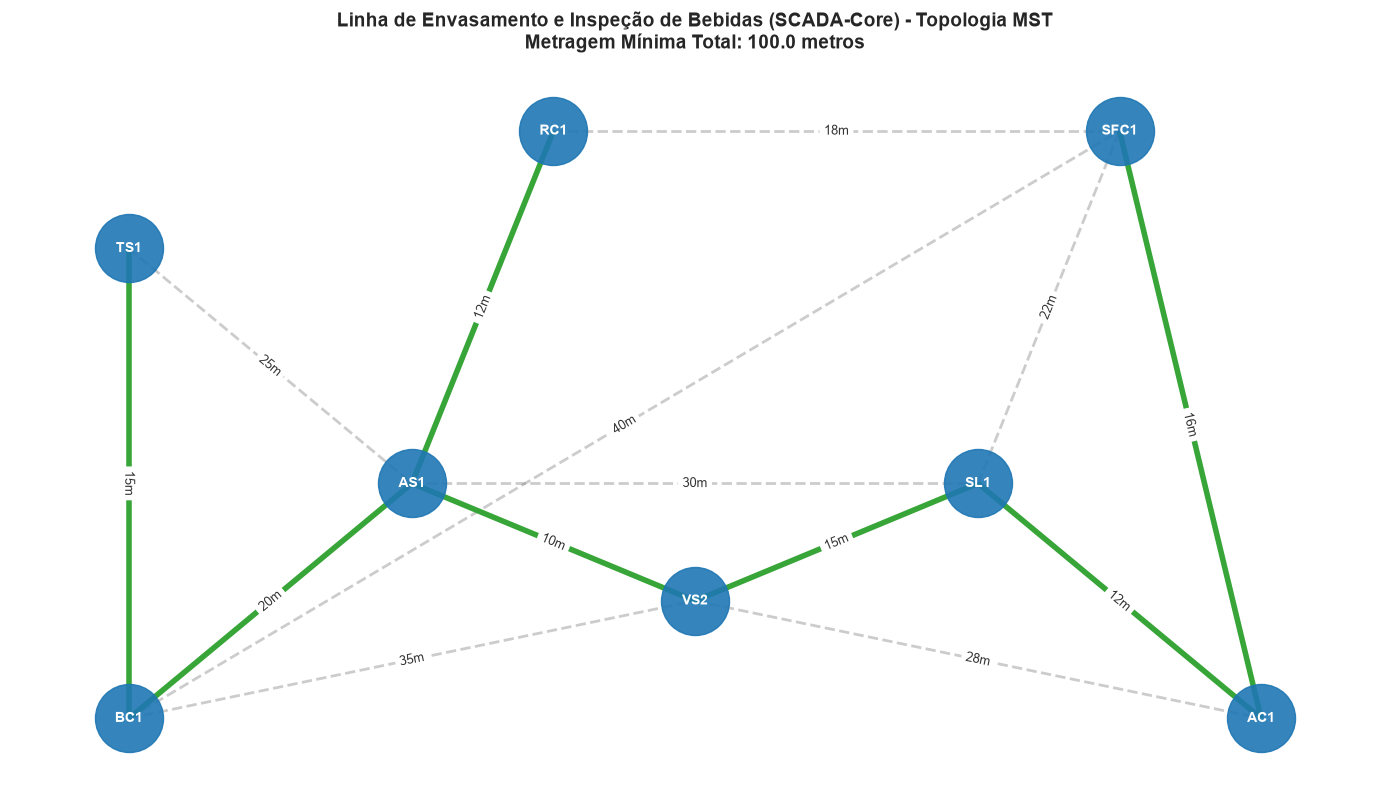

In [ ]:
# Criando o grafo NetworkX da Linha de Envase
G = nx.Graph()
for u, v, w in edges:
    G.add_edge(u, v, weight=w)

# Layout de posições físicas simulado ao longo da célula de envase
pos = {
    "TS1": (0, 3),
    "BC1": (0, 1),
    "AS1": (2, 2),
    "RC1": (3, 3.5),
    "VS2": (4, 1.5),
    "SL1": (6, 2),
    "AC1": (8, 1),
    "SFC1": (7, 3.5)
}

# Arestas selecionadas pela MST
mst_edge_pairs = set()
for u, v, w in kruskal_edges:
    mst_edge_pairs.add((u, v))
    mst_edge_pairs.add((v, u))

non_mst_edges = [e for e in G.edges() if (e[0], e[1]) not in mst_edge_pairs]
mst_edges_list = [e for e in G.edges() if (e[0], e[1]) in mst_edge_pairs]

fig, ax = plt.subplots(figsize=(14, 8))

# Desenhar vértices (Estações da Linha de Envase)
nx.draw_networkx_nodes(G, pos, node_size=2400, node_color='#1f77b4', alpha=0.9, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold', font_color='white', ax=ax)

# Desenhar arestas fora da MST (Redundantes/Descartadas)
nx.draw_networkx_edges(G, pos, edgelist=non_mst_edges, width=2, alpha=0.4, edge_color='gray', style='dashed', ax=ax)

# Desenhar arestas da MST (Rotas Ativas)
nx.draw_networkx_edges(G, pos, edgelist=mst_edges_list, width=4, alpha=0.95, edge_color='#2ca02c', ax=ax)

# Rótulos de pesos das arestas
edge_labels = nx.get_edge_attributes(G, 'weight')
formatted_labels = {k: f"{v:.0f}m" for k, v in edge_labels.items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=formatted_labels, font_size=9, font_color='#333333', ax=ax)

plt.title(f"Linha de Envasamento e Inspeção de Bebidas (SCADA-Core) - Topologia MST\nMetragem Mínima Total: {kruskal_weight:.1f} metros", fontsize=14, fontweight='bold', pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()

---
### 7. Análise Técnica e Conclusões da Engenharia (Grupo 3 — ECAA08)

1. **Redução de Custo de Capital (CAPEX):** A malha completa com todas as 14 rotas candidatas de eletrocalhas e *pipe racks* possuía um comprimento somado de **298 metros**. A topologia MST reduz a infraestrutura necessária para apenas **100 metros** (economia direta de **66,4%** em metragem de eletrocalhas inox, linhas de ar comprimido e cabos de instrumentação SCADA-Core).
2. **Escolha do Algoritmo no Ciclo de Vida da Linha de Envase:**
   - **Kruskal:** Recomendado durante o *Front-End Engineering Design* (FEED) da fábrica de bebidas, onde a matriz global de distâncias entre os tanques (`TS1`), bombas (`BC1`), acumulador (`AS1`) e módulos sobre a esteira (`RC1`, `VS2`, `SL1`, `AC1`, `SFC1`) está consolidada no projeto em planta baixa.
   - **Prim:** Recomendado durante a montagem eletromecânica e comissionamento em campo, pois expande o barramento SCADA-Core e o *manifold* pneumático de forma contínua a partir do setor de suprimento (`TS1`) até a extremidade final de inspeção de vedação (`SFC1`).